In [78]:
import pandas as pd 

df = pd.read_csv("../data/raw/spam.csv", encoding = "latin-1")
df = df.rename(columns={"v1": "message_type", "v2": "message"})
extra = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

df["message"] = df[["message"] + extra].apply(
    lambda row: ",".join(row.dropna()), axis = 1
)
df = df.drop(columns=extra)

print(df.shape)
print(df.info())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   message_type  5572 non-null   object
 1   message       5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [79]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    df.message, df.message_type, test_size = 0.2, stratify =df.message_type, random_state = 42
)

model = Pipeline([
    ("text", TfidfVectorizer(ngram_range = (1, 2), min_df = 2)),
    ("classifier", MultinomialNB(alpha = 0.1)),
])

model.fit(X_train, y_train)

Pipeline(steps=[('text', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classifier', MultinomialNB(alpha=0.1))])

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.99      0.90      0.94       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



Text(0.5, 1.0, 'Confusion Matrix')

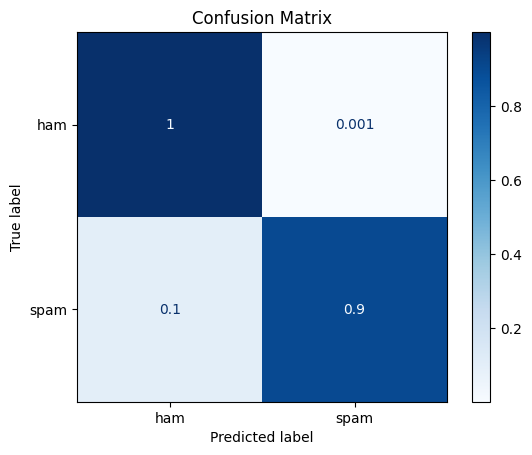

In [81]:
print(classification_report(y_test, model.predict(X_test)))
disp = ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test, display_labels = model.classes_, cmap = "Blues", normalize = "true"
)
disp.ax_.set_title("Confusion Matrix")

## False Negative Cases

In [88]:
test_predictions = model.predict(X_test)

errors = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": test_predictions,
})

missed_spam = errors[
    (errors["actual"] == "spam") &
    (errors["predicted"] == "ham")
]

missed_spam.head(10)

,message,actual,predicted
3057,You are now unsubscribed all services. Get ton...,spam,ham
5,FreeMsg Hey there darling it's been 3 week's n...,spam,ham
1021,Guess what! Somebody you know secretly fancies...,spam,ham
3748,Dear Voucher Holder 2 claim your 1st class air...,spam,ham
855,Talk sexy!! Make new friends or fall in love i...,spam,ham
3139,sexy sexy cum and text me im wet and warm and ...,spam,ham
1662,Hi if ur lookin 4 saucy daytime fun wiv busty ...,spam,ham
3979,ringtoneking 84484,spam,ham
4375,"If you don't, your prize will go to another cu...",spam,ham
3358,Sorry I missed your call let's talk when you h...,spam,ham


## Cross-validation 

In [83]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

scoring = {
    "accuracy": "accuracy",
    "spam_precision": make_scorer(precision_score, pos_label = "spam"),
    "spam_recall": make_scorer(recall_score, pos_label = "spam"),
    "spam_f1": make_scorer(f1_score, pos_label = "spam")
}
cv = StratifiedKFold(
    n_splits = 5, shuffle = True, random_state = 42
)

    

alpha=0.1: recall=0.906, f1=0.948
alpha=0.5: recall=0.816, f1=0.899
alpha=1.0: recall=0.726, f1=0.841


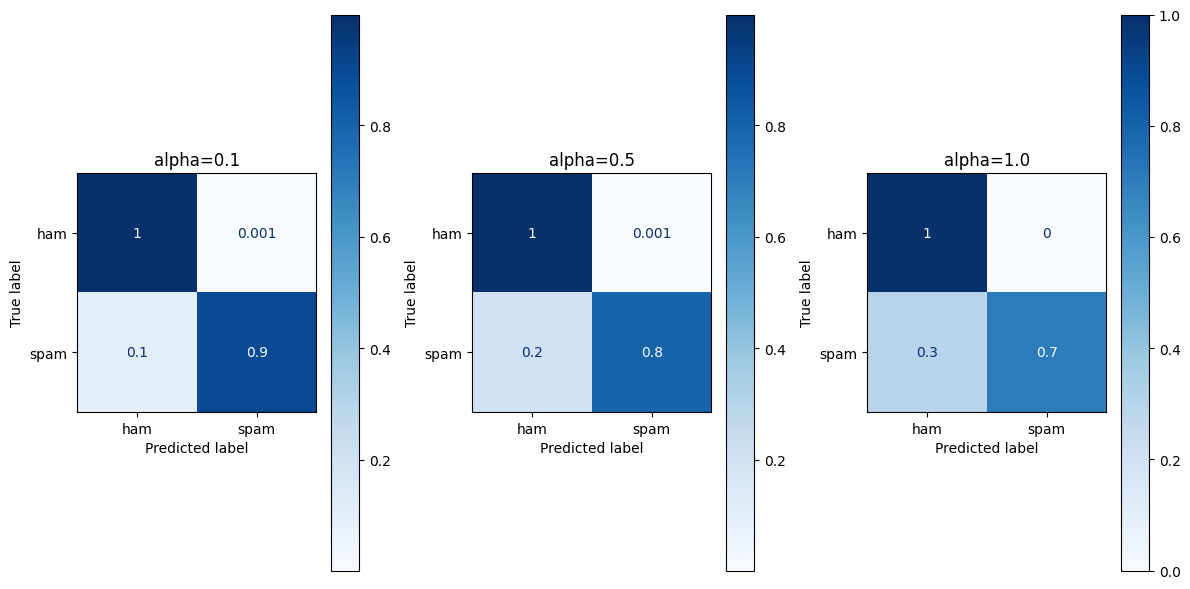

In [84]:
fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (12, 6))

for id, alpha in enumerate([0.1, 0.5, 1.0]):
    model.set_params(classifier__alpha = alpha)
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv = cv,
        scoring = scoring,
        return_train_score = False,
    )
    
    print(
        f"alpha={alpha}: "
        f"recall={scores['test_spam_recall'].mean():.3f}, "
        f"f1={scores['test_spam_f1'].mean():.3f}"
    )
    
    model.fit(X_train, y_train)
    
    axes[id] = ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, 
        display_labels = model.classes_, cmap = "Blues", normalize = "true", 
        ax = axes[id]
    )
    axes[id].ax_.set_title(f"alpha={alpha}")

plt.tight_layout()
plt.show()

## GridSearchCV

In [86]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "text__ngram_range": [(1, 1), (1, 2)],
    "text__min_df": [1, 2, 5, 10],
    "classifier__alpha": [0.01, 0.05, 0.1, 0.5, 1.0],
}

search = GridSearchCV(
    model,
    param_grid,
    cv = cv,
    scoring = scoring,
    n_jobs = -1,
    verbose = 1,
    refit = "spam_f1",
)

search.fit(X_train, y_train)

print(search.best_params_)
print(search.best_score_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
{'classifier__alpha': 0.01, 'text__min_df': 1, 'text__ngram_range': (1, 2)}
0.9537568002079407


In [87]:
import numpy as np
from sklearn.model_selection import cross_val_predict

best_model = search.best_estimator_

probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
)[:, 1]  # probability of "spam" in this model

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = np.where(
        probabilities >= threshold,
        "spam",
        "ham",
    )

    print(
        f"threshold={threshold}: "
        f"precision={precision_score(y_train, predictions, pos_label='spam'):.3f}, "
        f"recall={recall_score(y_train, predictions, pos_label='spam'):.3f}, "
        f"f1={f1_score(y_train, predictions, pos_label='spam'):.3f}"
    )

threshold=0.1: precision=0.904, recall=0.958, f1=0.930
threshold=0.2: precision=0.944, recall=0.952, f1=0.948
threshold=0.3: precision=0.964, recall=0.943, f1=0.954
threshold=0.4: precision=0.974, recall=0.940, f1=0.957
threshold=0.5: precision=0.976, recall=0.933, f1=0.954
threshold=0.6: precision=0.980, recall=0.925, f1=0.952
threshold=0.7: precision=0.986, recall=0.920, f1=0.952


# Final Test Set

1
              precision    recall  f1-score   support

         ham       1.00      0.95      0.97       966
        spam       0.76      0.97      0.85       149

    accuracy                           0.96      1115
   macro avg       0.88      0.96      0.91      1115
weighted avg       0.96      0.96      0.96      1115



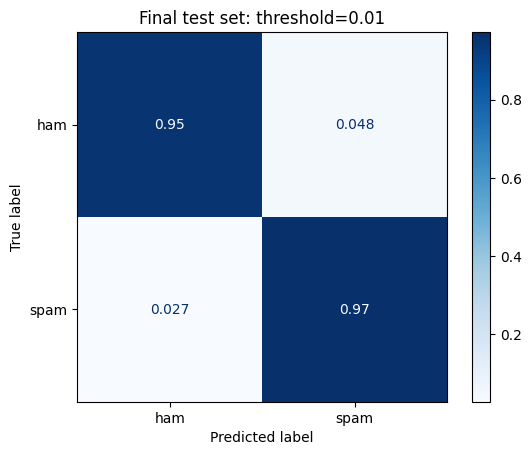

In [ ]:
chosen_probability_threshold = 0.01
spam_index = list(best_model.classes_).index("spam")
test_probabilities = best_model.predict_proba(X_test)[:, spam_index]

final_predictions = np.where(
    test_probabilities >= chosen_probability_threshold,
    "spam",
    "ham",
)

print(classification_report(y_test, final_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=["ham", "spam"],
    normalize="true",
    cmap="Blues",
)
plt.title(f"Final test set: threshold={chosen_probability_threshold}")
plt.show()